In [19]:
# YC1: Đọc dữ liệu từ file sepsis.csv, chia ngẫu nhiên thành 2 tập: train (75%) và test (25%).
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Đọc file .csv sử dụng pandas
columns = ['LOS', 'GENDER', 'AGE', 'WEIGHT', 'GCS TOTAL', 'TEMPERATURE', 'OUTCOME']
df = pd.read_csv('/content/drive/MyDrive/Học máy cơ bản/Practice03/sepsis.csv', usecols = columns)

# Chia dữ liệu: train (75% = 2424) and test (25% = 808)
X = df[['LOS', 'GENDER', 'AGE', 'WEIGHT', 'GCS TOTAL', 'TEMPERATURE']]

y = df['OUTCOME']
train_size = 2424
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

# Mã hóa One-hot (One-hot encoding)
y_train_onehot = keras.utils.to_categorical(y_train, 2)
y_test_onehot = keras.utils.to_categorical(y_test, 2)

print("Number of Training samples:", len(X_train))
print("Number of Testing samples:", len(X_test))

Number of Training samples: 2424
Number of Testing samples: 808


In [26]:
# YC2: Xây dựng mạng nơ-ron model_sepsis với 4 lớp ẩn (hidden layer),
# trong đó lớp ẩn 1 và 3 sử dụng Conv1D, lớp ẩn 2 và 4 lần lượt có 16, 32 units.
from tensorflow.keras.layers import Dense, Conv1D, Flatten, Reshape
from tensorflow.keras.models import Sequential

# Xây dựng mạng nơ-ron với 4 lớp ẩn
def model_sepsis():

    model = Sequential()

    # Xây dựng mạng: 1 Input + 4 Hidden + 1 Output
    model.add(Dense(8, input_dim=6, activation='relu'))
    model.add(Flatten())
    model.add(Dense(16, activation='relu'))
    model.add(Reshape((16, 1)))
    model.add(Conv1D(8, kernel_size=3, activation='relu'))
    model.add(Flatten())
    model.add(Dense(32, activation='relu'))
    model.add(Dense(2, activation='softmax'))

    return model

model = model_sepsis()

model.summary()

class PrintLossEvery5Epochs(tf.keras.callbacks.Callback):

    def on_epoch_end(self, epoch, logs=None):

        epoch_number = epoch + 1

        if epoch_number % 5 == 0:

            loss = logs.get("loss")
            accuracy = logs.get("accuracy")
            val_loss = logs.get("val_loss")
            val_accuracy = logs.get("val_accuracy")

            print(
                f"Epoch {epoch_number:3d}: "
                f"loss={loss:.4f}, "
                f"accuracy={accuracy:.4f}, "
                f"val_loss={val_loss:.4f}, "
                f"val_accuracy={val_accuracy:.4f}"
            )


class SaveModelEvery5Epochs(tf.keras.callbacks.Callback):

    def on_epoch_end(self, epoch, logs=None):

        epoch_number = epoch + 1

        if epoch_number % 5 == 0:

            filename = f"model_epoch_{epoch_number}.keras"

            self.model.save(filename)

            print(f"  -> Đã lưu model: {filename}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_21 (Dense)                │ (None, 8)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_14 (Flatten)            │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_14 (Reshape)            │ (None, 16, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_14 (Conv1D)              │ (None, 14, 8)          │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_15 (Flatten)            │ (None, 112)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 32)             │         3,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,914 (15.29 KB)

 Trainable params: 3,914 (15.29 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# YC3: Chọn hàm loss function và tối ưu hóa mô hình.
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

Epoch   5: loss=0.6321, accuracy=0.6534, val_loss=0.6095, val_accuracy=0.6676
  -> Đã lưu model: model_epoch_5.keras
Epoch  10: loss=0.6263, accuracy=0.6626, val_loss=0.5892, val_accuracy=0.6593
  -> Đã lưu model: model_epoch_10.keras
Epoch  15: loss=0.6005, accuracy=0.6830, val_loss=0.5789, val_accuracy=0.7088
  -> Đã lưu model: model_epoch_15.keras
Epoch  20: loss=0.5998, accuracy=0.6898, val_loss=0.5588, val_accuracy=0.7060
  -> Đã lưu model: model_epoch_20.keras
Epoch  25: loss=0.5943, accuracy=0.7000, val_loss=0.5744, val_accuracy=0.7363
  -> Đã lưu model: model_epoch_25.keras
Epoch  30: loss=0.6008, accuracy=0.6888, val_loss=0.5460, val_accuracy=0.7198
  -> Đã lưu model: model_epoch_30.keras
Epoch  35: loss=0.5830, accuracy=0.7010, val_loss=0.5524, val_accuracy=0.7170
  -> Đã lưu model: model_epoch_35.keras
Epoch  40: loss=0.5822, accuracy=0.7034, val_loss=0.5469, val_accuracy=0.7308
  -> Đã lưu model: model_epoch_40.keras
Epoch  45: loss=0.5876, accuracy=0.6971, val_loss=0.5497,

Epoch  50: loss=0.5810, accuracy=0.7053, val_loss=0.5486, val_accuracy=0.7143
  -> Đã lưu model: model_epoch_50.keras


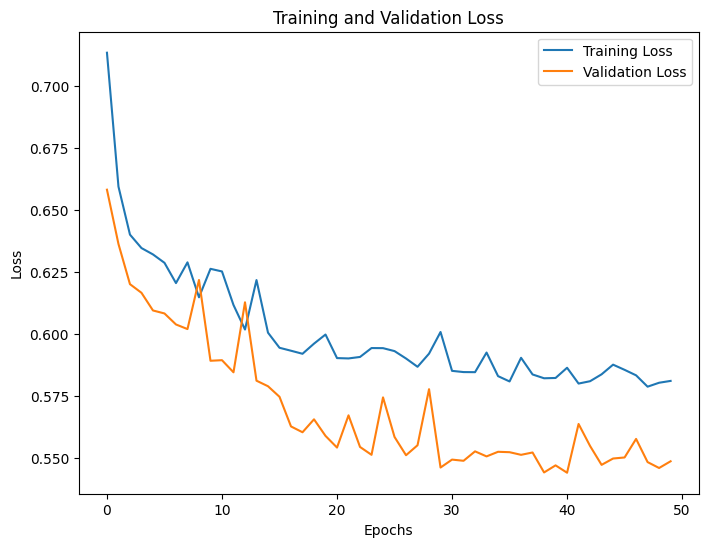

In [28]:
# YC4: Tiến hành huấn luyện mạng nơ-ron đã xây dựng ở trên với bộ dữ liệu đã tiền xử lý ở bước 1 với 50 epochs,
# batch size = 64, 15% cho tập validation và lưu lại các mô hình đã huấn luyện.
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.layers import Dropout

callbacks_50 = [
    PrintLossEvery5Epochs(),
    SaveModelEvery5Epochs()
]

history = model.fit(X_train, y_train_onehot, validation_split=0.15, epochs=50, batch_size=64, callbacks=callbacks_50, verbose=0)

model.save('model_model.h5')

plt.figure(figsize=(8, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [29]:
# YC5: Đánh giá mô hình đã huấn luyện trên tập test.
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

test_loss, test_acc = model.evaluate(X_test, y_test_onehot)
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)

from tensorflow.keras.models import Sequential, Model, load_model, Sequential

model_loaded = load_model('model_model.h5')

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7017 - loss: 0.5980 


Test loss: 0.5980191826820374
Test accuracy: 0.7017326951026917


In [30]:
# YC6: Huấn luyện lại mô hình với 100 epochs và đánh giá lại xem mô hình có cải thiện không.
model_100 = model_sepsis()

model_100.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

callbacks_100 = [PrintLossEvery5Epochs(), SaveModelEvery5Epochs()]

history = model.fit(X_train, y_train_onehot, validation_split=0.15, epochs=100, batch_size=64, callbacks=callbacks_100, verbose=0)

test_loss_100, test_accuracy_100 = model_100.evaluate(X_test, y_test_onehot, verbose=0)

print("Test Loss     :", test_loss_100)
print("Test Accuracy :", test_accuracy_100)
print("Test Accuracy (%):", test_accuracy_100 * 100)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch   5: loss=0.5800, accuracy=0.7097, val_loss=0.5471, val_accuracy=0.7308
  -> Đã lưu model: model_epoch_5.keras
Epoch  10: loss=0.5810, accuracy=0.7073, val_loss=0.5455, val_accuracy=0.7143
  -> Đã lưu model: model_epoch_10.keras
Epoch  15: loss=0.5770, accuracy=0.7015, val_loss=0.5554, val_accuracy=0.7253
  -> Đã lưu model: model_epoch_15.keras
Epoch  20: loss=0.5774, accuracy=0.7097, val_loss=0.5400, val_accuracy=0.7170
  -> Đã lưu model: model_epoch_20.keras
Epoch  25: loss=0.5760, accuracy=0.7180, val_loss=0.5448, val_accuracy=0.7280
  -> Đã lưu model: model_epoch_25.keras
Epoch  30: loss=0.5737, accuracy=0.7121, val_loss=0.5395, val_accuracy=0.7445
  -> Đã lưu model: model_epoch_30.keras
Epoch  35: loss=0.5736, accuracy=0.7121, val_loss=0.5525, val_accuracy=0.7308
  -> Đã lưu model: model_epoch_35.keras
Epoch  40: loss=0.5692, accuracy=0.7228, val_loss=0.5492, val_accuracy=0.7308
  -> Đã lưu model: model_epoch_40.keras
Epoch  45: loss=0.5754, accuracy=0.7083, val_loss=0.5574,